In [4]:
!mamba install pandas
mamba install scikit-learn
pip install seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge, emscripten-forge-3x

Solving environment...
Solving took 0.977 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge
mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, scikit-learn
Channels: emscripten-forge-4x, conda-forge, emscripten-forge-3x

Solving environment...
Solving took 1.112 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ brotli-python       1.2.0       py313h8faef1e_3      emscripten-forge-4x
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  py

In [5]:
import sys

print("Python version:", sys.version)
print("Platform:", sys.platform)
print("Python executable:", sys.executable)

Python version: 3.13.1 (main, Feb 18 2026, 20:57:27) [Clang 21.0.0git (https:/github.com/llvm/llvm-project 2f05451198e2f222ec66cec489
Platform: emscripten
Python executable: 


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import scipy
import sklearn

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All available libraries imported!")

NumPy: 2.5.4
SciPy: 1.18.0
Scikit-learn: 1.9.1
All available libraries imported!


In [12]:
import os

print("Current folder:", os.getcwd())
print("\nFiles available:")
print(os.listdir())

Current folder: /drive/notebooks/RetailMind - AI/Notebooks

Files available:
['.gitkeep', 'Day06.ipynb', 'Day2_Model_Comparison.ipynb', 'Day3_Model_Tuning.ipynb', 'Day4_Feature_Engineering.ipynb', 'Day4_Feature_Engineering_Ensemble.ipynb', 'Day5_ANN_Neural_Networks.ipynb', 'Train.ipynb', 'predict.ipynb', 'predict_cmp.ipynb']


In [14]:
import urllib.request
import os

base_url = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"

files = [
    "train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz"
]

for file in files:
    url = base_url + file
    try:
        urllib.request.urlretrieve(url, file)
        print("Downloaded:", file)
    except Exception as e:
        print("Failed:", file, e)

print("\nAvailable files:", os.listdir())

Downloaded: train-images-idx3-ubyte.gz
Downloaded: train-labels-idx1-ubyte.gz
Downloaded: t10k-images-idx3-ubyte.gz
Downloaded: t10k-labels-idx1-ubyte.gz

Available files: ['.gitkeep', 'Day06.ipynb', 'Day2_Model_Comparison.ipynb', 'Day3_Model_Tuning.ipynb', 'Day4_Feature_Engineering.ipynb', 'Day4_Feature_Engineering_Ensemble.ipynb', 'Day5_ANN_Neural_Networks.ipynb', 'Train.ipynb', 'predict.ipynb', 'predict_cmp.ipynb', 't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz', 'train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz']


In [15]:
import os

print([f for f in os.listdir() if f.endswith(".gz")])

['t10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz', 'train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz']


In [16]:
import gzip
import numpy as np
import struct

def load_images(filename):
    with gzip.open(filename, 'rb') as f:
        magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        return images.reshape(num, rows, cols, 1)

def load_labels(filename):
    with gzip.open(filename, 'rb') as f:
        magic, num = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

X_train = load_images("train-images-idx3-ubyte.gz")
y_train = load_labels("train-labels-idx1-ubyte.gz")

X_test = load_images("t10k-images-idx3-ubyte.gz")
y_test = load_labels("t10k-labels-idx1-ubyte.gz")

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)


Training images: (60000, 28, 28, 1)
Training labels: (60000,)
Testing images: (10000, 28, 28, 1)
Testing labels: (10000,)


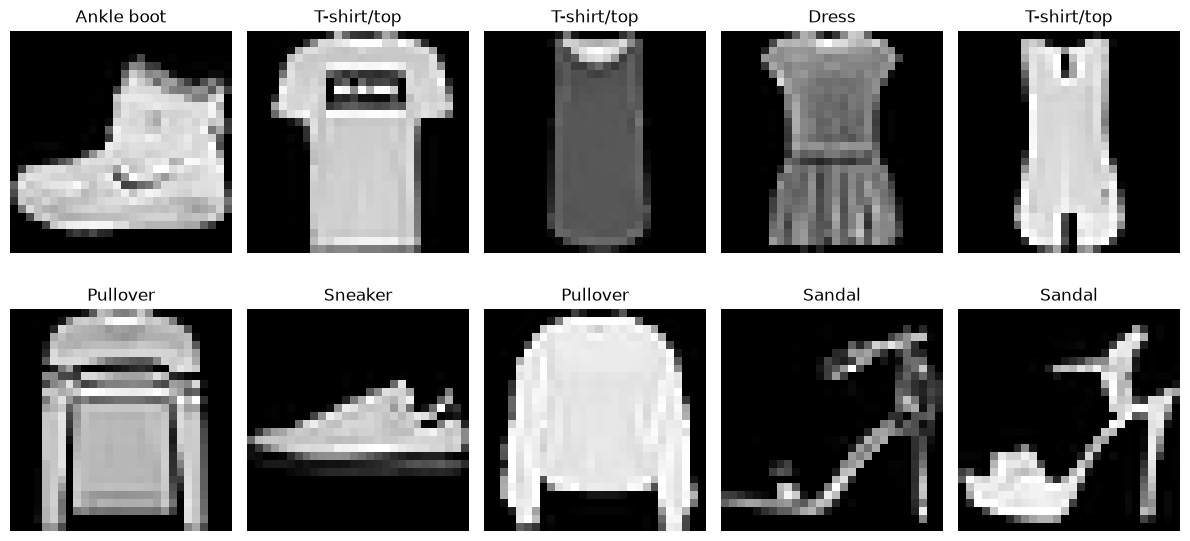

In [17]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress",
    "Coat", "Sandal", "Shirt", "Sneaker",
    "Bag", "Ankle boot"
]

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [18]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


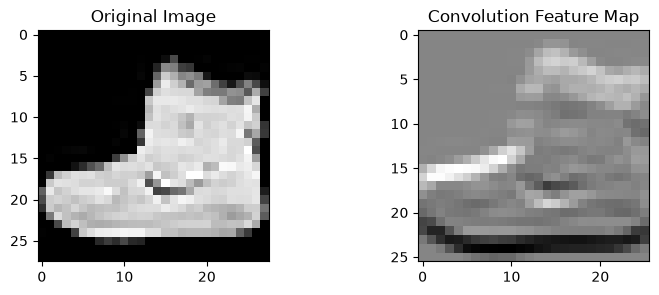

In [19]:
from scipy.signal import correlate2d

# Example image
sample_image = X_train[0].squeeze()

# 3x3 edge detection filter
kernel = np.array([
    [-1, -1, -1],
    [ 0,  0,  0],
    [ 1,  1,  1]
])

feature_map = correlate2d(
    sample_image,
    kernel,
    mode="valid"
)

plt.figure(figsize=(9, 3))

plt.subplot(1, 2, 1)
plt.imshow(sample_image, cmap="gray")
plt.title("Original Image")

plt.subplot(1, 2, 2)
plt.imshow(feature_map, cmap="gray")
plt.title("Convolution Feature Map")

plt.show()


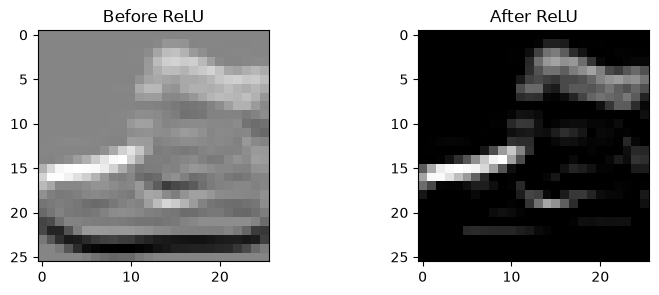

In [20]:

relu_output = np.maximum(feature_map, 0)

plt.figure(figsize=(9, 3))

plt.subplot(1, 2, 1)
plt.imshow(feature_map, cmap="gray")
plt.title("Before ReLU")

plt.subplot(1, 2, 2)
plt.imshow(relu_output, cmap="gray")
plt.title("After ReLU")

plt.show()


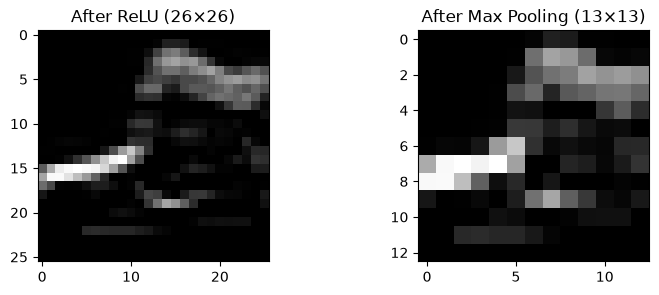

Pooled shape: (13, 13)


In [21]:

def max_pooling(image, pool_size=2):

    h, w = image.shape

    output = np.zeros((h // pool_size, w // pool_size))

    for i in range(0, h, pool_size):
        for j in range(0, w, pool_size):

            region = image[
                i:i+pool_size,
                j:j+pool_size
            ]

            output[i//pool_size, j//pool_size] = np.max(region)

    return output


pooled_output = max_pooling(relu_output)

plt.figure(figsize=(9, 3))

plt.subplot(1, 2, 1)
plt.imshow(relu_output, cmap="gray")
plt.title("After ReLU (26×26)")

plt.subplot(1, 2, 2)
plt.imshow(pooled_output, cmap="gray")
plt.title("After Max Pooling (13×13)")

plt.show()

print("Pooled shape:", pooled_output.shape)


In [22]:

flattened = pooled_output.flatten()

print("Original shape:", pooled_output.shape)
print("Flattened shape:", flattened.shape)
print("Total features:", len(flattened))


Original shape: (13, 13)
Flattened shape: (169,)
Total features: 169


In [23]:

def softmax(x):
    exp_values = np.exp(x - np.max(x))
    return exp_values / np.sum(exp_values)

# Example output scores from 10 neurons
scores = np.random.randn(10)

probabilities = softmax(scores)

print("Probabilities:", probabilities)
print("Sum:", probabilities.sum())
print("Predicted class:", np.argmax(probabilities))


Probabilities: [0.18523886 0.02787955 0.23834628 0.01718714 0.00328267 0.0948885
 0.29760801 0.06058936 0.04105856 0.03392108]
Sum: 0.9999999999999999
Predicted class: 6


In [24]:

from sklearn.model_selection import train_test_split

# Flatten images for the fully connected classifier
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

# Use a manageable training sample
X_train_small, _, y_train_small, _ = train_test_split(
    X_train_flat,
    y_train,
    train_size=10000,
    random_state=42,
    stratify=y_train
)

print("Training samples:", X_train_small.shape)
print("Testing samples:", X_test_flat.shape)


Training samples: (10000, 784)
Testing samples: (10000, 784)


In [25]:

from sklearn.neural_network import MLPClassifier

model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    max_iter=15,
    random_state=42,
    verbose=True
)

model.fit(X_train_small, y_train_small)

print("Training completed!")


Iteration 1, loss = 0.99684942
Iteration 2, loss = 0.56361938
Iteration 3, loss = 0.48782891
Iteration 4, loss = 0.44922954
Iteration 5, loss = 0.41935641
Iteration 6, loss = 0.40300140
Iteration 7, loss = 0.37854534
Iteration 8, loss = 0.37557882
Iteration 9, loss = 0.35332078
Iteration 10, loss = 0.33759654
Iteration 11, loss = 0.32470480
Iteration 12, loss = 0.31768045
Iteration 13, loss = 0.30661660
Iteration 14, loss = 0.29602066
Iteration 15, loss = 0.28487921


/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


Training completed!


In [26]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test_flat)

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))


Test Accuracy: 0.8531

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.73      0.79      1000
     Trouser       0.98      0.96      0.97      1000
    Pullover       0.77      0.74      0.75      1000
       Dress       0.85      0.88      0.86      1000
        Coat       0.76      0.77      0.77      1000
      Sandal       0.97      0.93      0.95      1000
       Shirt       0.60      0.69      0.64      1000
     Sneaker       0.87      0.97      0.92      1000
         Bag       0.94      0.96      0.95      1000
  Ankle boot       0.97      0.91      0.94      1000

    accuracy                           0.85     10000
   macro avg       0.86      0.85      0.85     10000
weighted avg       0.86      0.85      0.85     10000



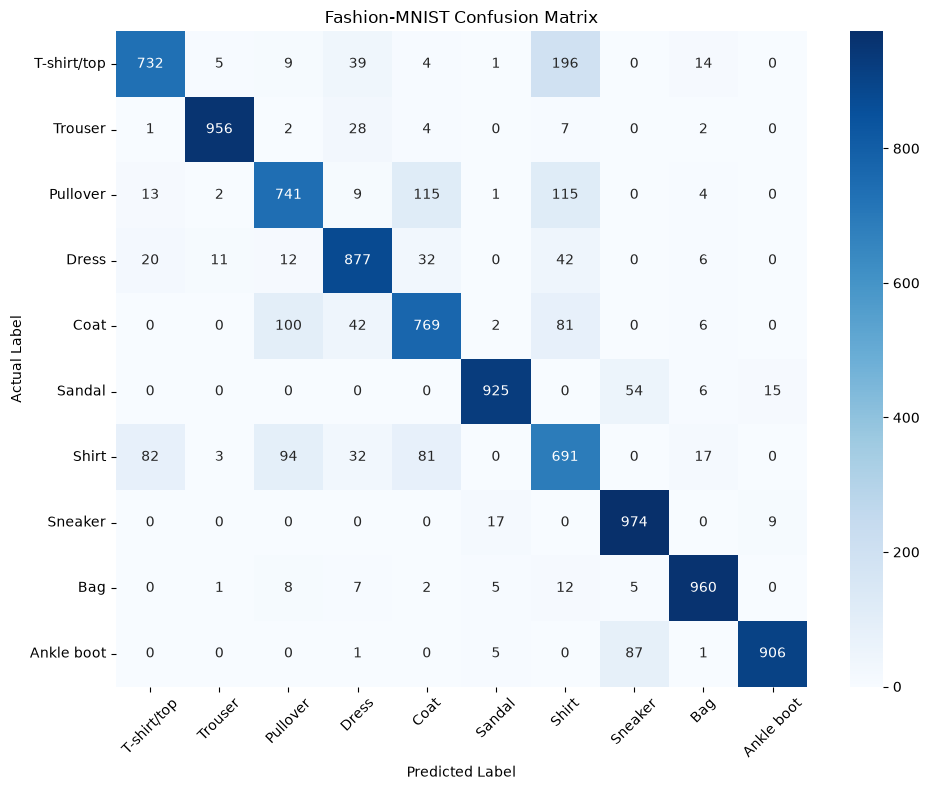

In [27]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fashion-MNIST Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [28]:

from sklearn.neural_network import MLPClassifier

model = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    max_iter=15,
    random_state=42,
    verbose=True
)

model.fit(X_train_small, y_train_small)

print("Training completed!")


Iteration 1, loss = 0.99684942
Iteration 2, loss = 0.56361938
Iteration 3, loss = 0.48782891
Iteration 4, loss = 0.44922954
Iteration 5, loss = 0.41935641
Iteration 6, loss = 0.40300140
Iteration 7, loss = 0.37854534
Iteration 8, loss = 0.37557882
Iteration 9, loss = 0.35332078
Iteration 10, loss = 0.33759654
Iteration 11, loss = 0.32470480
Iteration 12, loss = 0.31768045
Iteration 13, loss = 0.30661660
Iteration 14, loss = 0.29602066
Iteration 15, loss = 0.28487921


/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (15) reached and the optimization hasn't converged yet.
  warnings.warn(


Training completed!


In [29]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred = model.predict(X_test_flat)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="weighted"
)

recall = recall_score(
    y_test, y_pred, average="weighted"
)

f1 = f1_score(
    y_test, y_pred, average="weighted"
)

print("MODEL EVALUATION")
print("-------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))


MODEL EVALUATION
-------------------------
Accuracy : 0.8531
Precision: 0.8579103315293515
Recall   : 0.8531
F1 Score : 0.8541396260335367

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.86      0.73      0.79      1000
     Trouser       0.98      0.96      0.97      1000
    Pullover       0.77      0.74      0.75      1000
       Dress       0.85      0.88      0.86      1000
        Coat       0.76      0.77      0.77      1000
      Sandal       0.97      0.93      0.95      1000
       Shirt       0.60      0.69      0.64      1000
     Sneaker       0.87      0.97      0.92      1000
         Bag       0.94      0.96      0.95      1000
  Ankle boot       0.97      0.91      0.94      1000

    accuracy                           0.85     10000
   macro avg       0.86      0.85      0.85     10000
weighted avg       0.86      0.85      0.85     10000



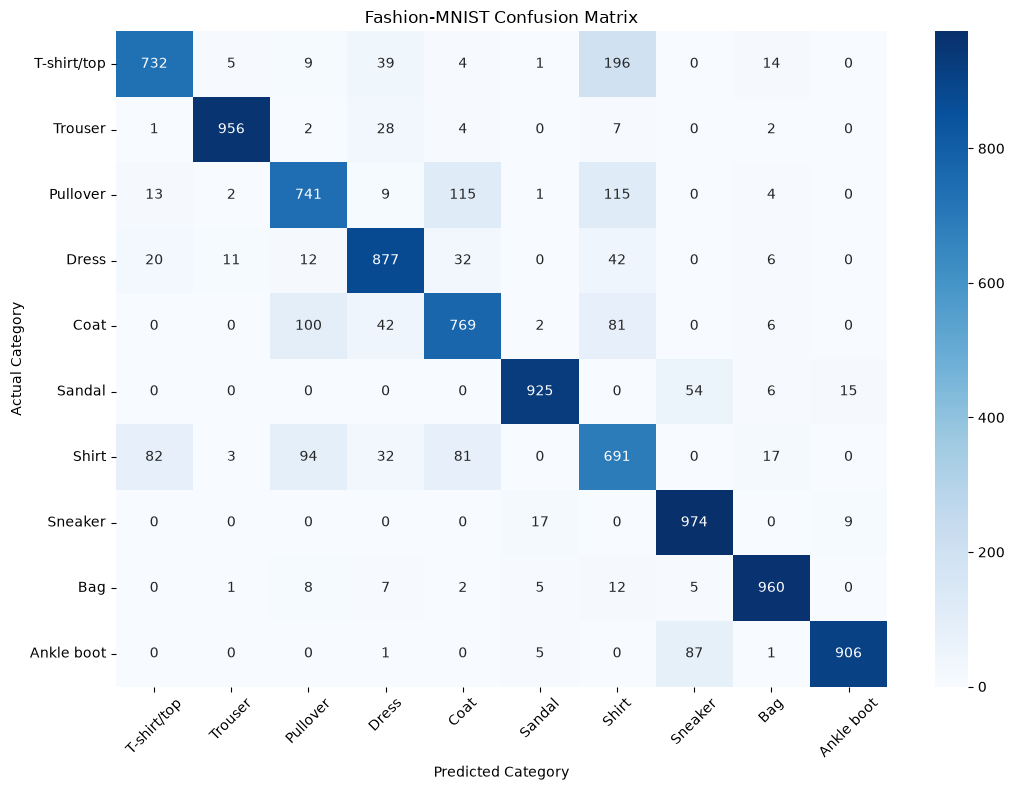

In [30]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(11, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Fashion-MNIST Confusion Matrix")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


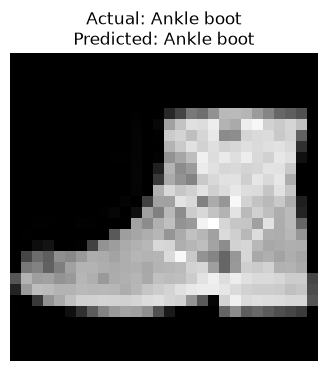

In [31]:

import random

index = random.randint(0, len(X_test) - 1)

image = X_test[index]

prediction = model.predict(
    image.reshape(1, -1)
)[0]

plt.figure(figsize=(4, 4))
plt.imshow(image.reshape(28, 28), cmap="gray")
plt.title(
    f"Actual: {class_names[y_test[index]]}\n"
    f"Predicted: {class_names[prediction]}"
)
plt.axis("off")
plt.show()


In [32]:

import os
import joblib

# Create Models folder if it doesn't exist
os.makedirs("../Models", exist_ok=True)

# Save trained model
joblib.dump(
    model,
    "../Models/day6_fashion_classifier.joblib"
)

print("Model saved successfully!")


Model saved successfully!


In [33]:

metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1
}

metrics_df = pd.DataFrame(
    list(metrics.items()),
    columns=["Metric", "Score"]
)

metrics_df.to_csv(
    "../Models/day6_evaluation_metrics.csv",
    index=False
)

print(metrics_df)


      Metric    Score
0   Accuracy  0.85310
1  Precision  0.85791
2     Recall  0.85310
3   F1_Score  0.85414


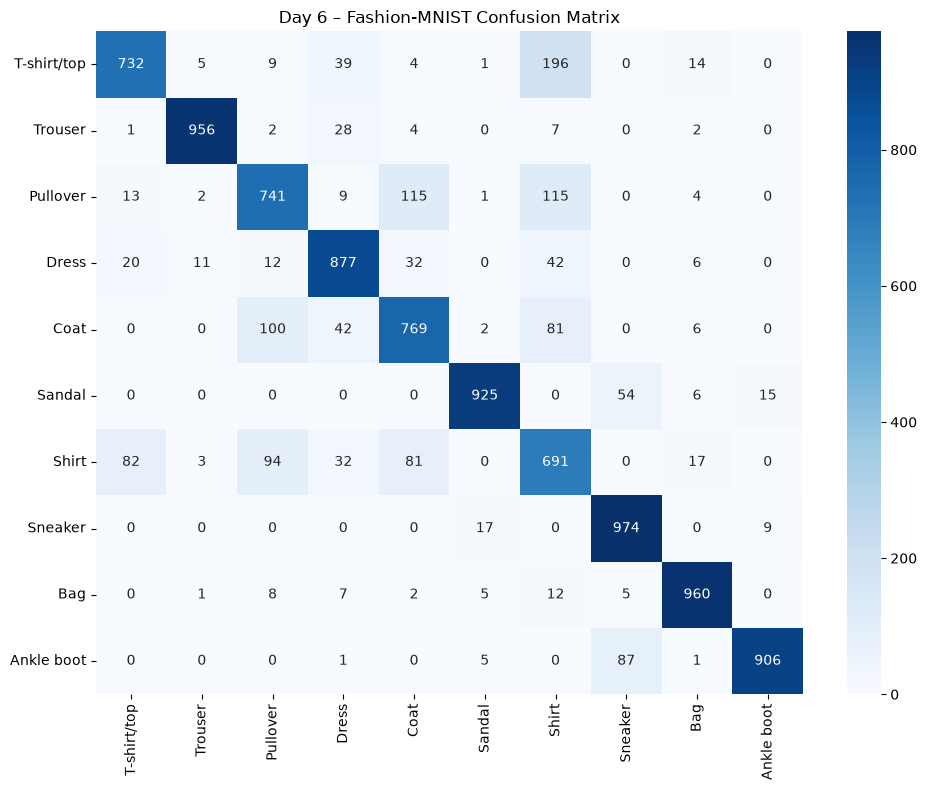

In [34]:

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Day 6 – Fashion-MNIST Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "../Models/day6_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
